# A4v2. 4G LTE tarmog‘ida radioresurslarni taqsimlash jarayonini modellashtirish

**Muhit / Среда:** Python + Google Colab  
**Davomiyligi / Продолжительность:** 2 soat  
**Variant:** `VARIANT = 1` → 1–15.

Model 100 ta 1-ms TTI, sintetik frequency-selective per-PRB CQI, 3GPP CQI Table 1 efficiency qiymatlari va RR / Max-CQI / historical PF schedulerlarini taqqoslaydi.

## 1. Model funksiyalari / Функции модели

In [1]:
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

PRB_MAP = {1.4: 6, 3.0: 15, 5.0: 25, 10.0: 50, 15.0: 75, 20.0: 100}
CQI_EFF = {
    1: 0.1523, 2: 0.2344, 3: 0.3770, 4: 0.6016, 5: 0.8770,
    6: 1.1758, 7: 1.4766, 8: 1.9141, 9: 2.4063, 10: 2.7305,
    11: 3.3223, 12: 3.9023, 13: 4.5234, 14: 5.1152, 15: 5.5547,
}
PRB_BW_MHZ = 0.18
TTI_S = 0.001

VARIANTS = [
    dict(variant=1, bandwidth_mhz=10, n_ue=8, cqi_min=4, cqi_max=13, demand_min_mbps=1.5, demand_max_mbps=6.0, seed=301),
    dict(variant=2, bandwidth_mhz=5, n_ue=6, cqi_min=3, cqi_max=12, demand_min_mbps=1.0, demand_max_mbps=5.0, seed=302),
    dict(variant=3, bandwidth_mhz=10, n_ue=10, cqi_min=2, cqi_max=14, demand_min_mbps=2.0, demand_max_mbps=8.0, seed=303),
    dict(variant=4, bandwidth_mhz=5, n_ue=8, cqi_min=5, cqi_max=15, demand_min_mbps=1.0, demand_max_mbps=4.0, seed=304),
    dict(variant=5, bandwidth_mhz=10, n_ue=12, cqi_min=3, cqi_max=11, demand_min_mbps=2.0, demand_max_mbps=7.0, seed=305),
    dict(variant=6, bandwidth_mhz=5, n_ue=7, cqi_min=2, cqi_max=10, demand_min_mbps=1.0, demand_max_mbps=6.0, seed=306),
    dict(variant=7, bandwidth_mhz=10, n_ue=9, cqi_min=6, cqi_max=15, demand_min_mbps=2.0, demand_max_mbps=9.0, seed=307),
    dict(variant=8, bandwidth_mhz=5, n_ue=10, cqi_min=4, cqi_max=13, demand_min_mbps=1.0, demand_max_mbps=5.0, seed=308),
    dict(variant=9, bandwidth_mhz=10, n_ue=6, cqi_min=1, cqi_max=15, demand_min_mbps=3.0, demand_max_mbps=10.0, seed=309),
    dict(variant=10, bandwidth_mhz=5, n_ue=12, cqi_min=5, cqi_max=12, demand_min_mbps=1.0, demand_max_mbps=4.0, seed=310),
    dict(variant=11, bandwidth_mhz=10, n_ue=8, cqi_min=2, cqi_max=9, demand_min_mbps=2.0, demand_max_mbps=8.0, seed=311),
    dict(variant=12, bandwidth_mhz=5, n_ue=9, cqi_min=7, cqi_max=15, demand_min_mbps=2.0, demand_max_mbps=6.0, seed=312),
    dict(variant=13, bandwidth_mhz=10, n_ue=11, cqi_min=3, cqi_max=14, demand_min_mbps=1.0, demand_max_mbps=9.0, seed=313),
    dict(variant=14, bandwidth_mhz=5, n_ue=6, cqi_min=1, cqi_max=11, demand_min_mbps=1.0, demand_max_mbps=7.0, seed=314),
    dict(variant=15, bandwidth_mhz=10, n_ue=12, cqi_min=4, cqi_max=15, demand_min_mbps=3.0, demand_max_mbps=10.0, seed=315),
]


def prb_count(bandwidth_mhz: float) -> int:
    bw = float(bandwidth_mhz)
    if bw not in PRB_MAP:
        raise ValueError(f"Unsupported LTE bandwidth: {bandwidth_mhz} MHz")
    return PRB_MAP[bw]


def cqi_efficiency(cqi: int) -> float:
    c = int(cqi)
    if c not in CQI_EFF:
        raise ValueError("CQI Table 1 teaching model supports CQI 1..15; CQI 0 is out of range")
    return CQI_EFF[c]


def jain_index(x) -> float:
    x = np.asarray(x, dtype=float)
    denom = x.size * np.sum(x * x)
    return 0.0 if denom <= 0 else float((np.sum(x) ** 2) / denom)


def fairness_metrics(throughput_mbps, demand_mbps) -> dict:
    thr = np.asarray(throughput_mbps, dtype=float)
    demand = np.asarray(demand_mbps, dtype=float)
    sat = np.divide(thr, demand, out=np.zeros_like(thr), where=demand > 0)
    sat = np.clip(sat, 0.0, 1.0)
    return {
        "throughput_jain": jain_index(thr),
        "satisfaction_jain": jain_index(sat),
        "mean_satisfaction_pct": 100.0 * float(np.mean(sat)),
        "p5_satisfaction_pct": 100.0 * float(np.percentile(sat, 5)),
        "min_satisfaction_pct": 100.0 * float(np.min(sat)),
        "starved_ue_pct": 100.0 * float(np.mean(thr <= 1e-9)),
        "satisfaction": sat,
    }


def make_ue_parameters(v: dict) -> pd.DataFrame:
    rng = np.random.default_rng(int(v["seed"]))
    n = int(v["n_ue"])
    mean_cqi = rng.integers(int(v["cqi_min"]), int(v["cqi_max"]) + 1, size=n)
    demand = rng.uniform(float(v["demand_min_mbps"]), float(v["demand_max_mbps"]), size=n)
    eta = np.array([cqi_efficiency(c) for c in mean_cqi], dtype=float)
    nominal_prb_rate = PRB_BW_MHZ * eta
    return pd.DataFrame({
        "ue": np.arange(1, n + 1),
        "mean_cqi": mean_cqi,
        "mean_spectral_eff_bps_hz": eta,
        "nominal_prb_rate_mbps": nominal_prb_rate,
        "demand_mbps": demand,
    })


def generate_cqi_cube(mean_cqi, n_tti: int, n_prb: int, seed: int) -> np.ndarray:
    means = np.asarray(mean_cqi, dtype=int)
    rng = np.random.default_rng(int(seed))
    offsets = rng.choice(
        np.array([-2, -1, 0, 1, 2], dtype=int),
        size=(int(n_tti), means.size, int(n_prb)),
        p=np.array([0.10, 0.20, 0.40, 0.20, 0.10]),
    )
    cube = means[None, :, None] + offsets
    return np.clip(cube, 1, 15).astype(np.int8)


def _rate_cube_from_cqi(cqi_cube: np.ndarray) -> np.ndarray:
    lut = np.zeros(16, dtype=float)
    for c, e in CQI_EFF.items():
        lut[c] = e
    return PRB_BW_MHZ * lut[np.asarray(cqi_cube, dtype=int)]


def prepare_scenario(
    v: dict,
    n_tti: int = 100,
    load_factor: float = 1.0,
    ue_df: pd.DataFrame | None = None,
    cqi_cube: np.ndarray | None = None,
    n_prb: int | None = None,
) -> dict:
    ue = make_ue_parameters(v) if ue_df is None else ue_df.copy()
    nprb = prb_count(v["bandwidth_mhz"]) if n_prb is None else int(n_prb)
    means = ue["mean_cqi"].to_numpy(int)
    if cqi_cube is None:
        # Generate a common 100-PRB master cube and slice it so that the base
        # scenario exactly matches the overlapping PRBs used in bandwidth sensitivity.
        master_prb = max(100, nprb)
        cqi_cube = generate_cqi_cube(means, n_tti=n_tti, n_prb=master_prb, seed=int(v["seed"]) + 10000)[:, :, :nprb]
    else:
        cqi_cube = np.asarray(cqi_cube, dtype=np.int8)
        if cqi_cube.shape != (int(n_tti), len(ue), nprb):
            raise ValueError(f"cqi_cube shape must be {(int(n_tti), len(ue), nprb)}, got {cqi_cube.shape}")
    demand = ue["demand_mbps"].to_numpy(float) * float(load_factor)
    return {
        "v": dict(v),
        "ue_df": ue,
        "n_tti": int(n_tti),
        "n_prb": nprb,
        "cqi_cube": cqi_cube,
        "rate_cube_mbps": _rate_cube_from_cqi(cqi_cube),
        "demand_mbps": demand,
        "load_factor": float(load_factor),
    }


def simulate_scheduler(scenario: dict, scheduler: str, pf_alpha: float = 0.02, pf_epsilon_mbps: float = 0.05) -> dict:
    key = scheduler.strip().upper().replace("_", "-")
    if key == "MAXCQI":
        key = "MAX-CQI"
    if key not in {"RR", "MAX-CQI", "PF"}:
        raise ValueError("scheduler must be RR, Max-CQI, or PF")

    rates = np.asarray(scenario["rate_cube_mbps"], dtype=float)
    n_tti, n_ue, n_prb = rates.shape
    demand = np.asarray(scenario["demand_mbps"], dtype=float)
    queue_mbit = np.zeros(n_ue, dtype=float)
    served_mbit = np.zeros(n_ue, dtype=float)
    alloc = np.zeros(n_ue, dtype=int)
    used = 0
    rr_pointer = 0
    pf_avg = np.full(n_ue, float(pf_epsilon_mbps), dtype=float)
    pf_trace = np.zeros((n_tti, n_ue), dtype=float) if key == "PF" else None

    for t in range(n_tti):
        queue_mbit += demand * TTI_S
        served_this_tti_mbit = np.zeros(n_ue, dtype=float)
        for r in range(n_prb):
            active = np.where(queue_mbit > 1e-12)[0]
            if active.size == 0:
                break
            if key == "RR":
                chosen = None
                active_set = set(int(i) for i in active)
                for step in range(n_ue):
                    idx = (rr_pointer + step) % n_ue
                    if idx in active_set:
                        chosen = idx
                        rr_pointer = (idx + 1) % n_ue
                        break
            elif key == "MAX-CQI":
                chosen = int(active[np.argmax(rates[t, active, r])])
            else:
                metric = rates[t, active, r] / (pf_avg[active] + pf_epsilon_mbps)
                chosen = int(active[np.argmax(metric)])

            capacity_mbit = rates[t, chosen, r] * TTI_S
            service_mbit = min(queue_mbit[chosen], capacity_mbit)
            if service_mbit <= 0:
                continue
            queue_mbit[chosen] -= service_mbit
            served_mbit[chosen] += service_mbit
            served_this_tti_mbit[chosen] += service_mbit
            alloc[chosen] += 1
            used += 1

        if key == "PF":
            useful_rate_this_tti = served_this_tti_mbit / TTI_S
            pf_avg = (1.0 - pf_alpha) * pf_avg + pf_alpha * useful_rate_this_tti
            pf_trace[t] = pf_avg

    duration_s = n_tti * TTI_S
    throughput = served_mbit / duration_s
    throughput = np.minimum(throughput, demand + 1e-12)
    fairness = fairness_metrics(throughput, demand)
    unmet = np.maximum(demand - throughput, 0.0)
    available = n_tti * n_prb
    mean_used_prbs_per_tti = used / n_tti
    occupied_bw_mhz = mean_used_prbs_per_tti * PRB_BW_MHZ
    effective_se = float(np.sum(throughput) / occupied_bw_mhz) if occupied_bw_mhz > 0 else 0.0
    kpi = {
        "cell_throughput_mbps": float(np.sum(throughput)),
        "throughput_jain": fairness["throughput_jain"],
        "satisfaction_jain": fairness["satisfaction_jain"],
        "mean_satisfaction_pct": fairness["mean_satisfaction_pct"],
        "p5_satisfaction_pct": fairness["p5_satisfaction_pct"],
        "min_satisfaction_pct": fairness["min_satisfaction_pct"],
        "starved_ue_pct": fairness["starved_ue_pct"],
        "total_unmet_demand_mbps": float(np.sum(unmet)),
        "resource_utilization_pct": 100.0 * used / available,
        "used_prb_opportunities": int(used),
        "available_prb_opportunities": int(available),
        "effective_useful_spectral_eff_bps_hz": effective_se,
    }
    return {
        "scheduler": "Max-CQI" if key == "MAX-CQI" else key,
        "throughput_mbps": throughput,
        "unmet_demand_mbps": unmet,
        "satisfaction": fairness["satisfaction"],
        "alloc_prbs": alloc,
        "kpi": kpi,
        "pf_avg_throughput_trace": pf_trace,
    }


def run_all_schedulers(scenario: dict) -> dict:
    return {s: simulate_scheduler(scenario, s) for s in ("RR", "Max-CQI", "PF")}


def bandwidth_sensitivity(v: dict, n_tti: int = 100) -> pd.DataFrame:
    base_bw = float(v["bandwidth_mhz"])
    if base_bw not in (5.0, 10.0):
        raise ValueError("Teaching bandwidth sensitivity expects 5->10 or 10->20 MHz")
    wide_bw = base_bw * 2.0
    ue = make_ue_parameters(v)
    mean_cqi = ue["mean_cqi"].to_numpy(int)
    max_prb = max(100, prb_count(wide_bw))
    cube_max = generate_cqi_cube(mean_cqi, n_tti, max_prb, seed=int(v["seed"]) + 10000)
    rows = []
    for bw in (base_bw, wide_bw):
        vv = dict(v)
        vv["bandwidth_mhz"] = bw
        nprb = prb_count(bw)
        sc = prepare_scenario(vv, n_tti=n_tti, ue_df=ue, cqi_cube=cube_max[:, :, :nprb], n_prb=nprb)
        for s, res in run_all_schedulers(sc).items():
            k = res["kpi"]
            rows.append({"bandwidth_mhz": bw, "available_prbs": nprb, "scheduler": s, **k})
    return pd.DataFrame(rows)


def load_sweep(v: dict, load_factors=(0.5, 1.0, 1.5, 2.0), n_tti: int = 100) -> pd.DataFrame:
    ue = make_ue_parameters(v)
    nprb = prb_count(v["bandwidth_mhz"])
    master = generate_cqi_cube(ue["mean_cqi"].to_numpy(int), n_tti, max(100, nprb), seed=int(v["seed"]) + 10000)
    cube = master[:, :, :nprb]
    rows = []
    for rho in load_factors:
        sc = prepare_scenario(v, n_tti=n_tti, load_factor=float(rho), ue_df=ue, cqi_cube=cube, n_prb=nprb)
        for s, res in run_all_schedulers(sc).items():
            rows.append({"load_factor": float(rho), "scheduler": s, **res["kpi"]})
    return pd.DataFrame(rows)


def build_summary_tables(v: dict, n_tti: int = 100):
    scenario = prepare_scenario(v, n_tti=n_tti)
    results = run_all_schedulers(scenario)
    kpi_rows = []
    alloc_rows = []
    ue = scenario["ue_df"]
    for s, res in results.items():
        kpi_rows.append({"scheduler": s, **res["kpi"]})
        for i, row in ue.iterrows():
            alloc_rows.append({
                "scheduler": s,
                "ue": int(row["ue"]),
                "mean_cqi": int(row["mean_cqi"]),
                "demand_mbps": float(scenario["demand_mbps"][i]),
                "allocated_prb_opportunities": int(res["alloc_prbs"][i]),
                "throughput_mbps": float(res["throughput_mbps"][i]),
                "satisfaction_pct": 100.0 * float(res["satisfaction"][i]),
                "unmet_demand_mbps": float(res["unmet_demand_mbps"][i]),
            })
    return scenario, results, pd.DataFrame(kpi_rows), pd.DataFrame(alloc_rows)

## 2. Variantni tanlash va UE/channel parametrlarini yaratish

In [2]:
VARIANT = 1  # 1..15
N_TTI = 100
v = dict(VARIANTS[VARIANT-1])
scenario = prepare_scenario(v, n_tti=N_TTI)
ue_df = scenario["ue_df"].copy()

cqi = scenario["cqi_cube"]
cqi_stats_df = pd.DataFrame({
    "UE": ue_df["ue"].astype(int),
    "mean_CQI_parameter": ue_df["mean_cqi"].astype(int),
    "realized_CQI_mean": cqi.mean(axis=(0,2)),
    "realized_CQI_std": cqi.std(axis=(0,2)),
    "realized_CQI_min": cqi.min(axis=(0,2)),
    "realized_CQI_max": cqi.max(axis=(0,2)),
})
print('Variant'+':', VARIANT)
print('Parametrlar'+':', v)
print('Har bir TTI dagi PRBlar'+':', scenario['n_prb'])
print('Scheduling gorizonti, TTI'+':', N_TTI)
print('\nUE parametrlari:')
display(ue_df.round(4))
print('\nRealizatsiya qilingan per-PRB CQI statistikasi:')
display(cqi_stats_df.round(3))

Variant: 1
Parametrlar: {'variant': 1, 'bandwidth_mhz': 10, 'n_ue': 8, 'cqi_min': 4, 'cqi_max': 13, 'demand_min_mbps': 1.5, 'demand_max_mbps': 6.0, 'seed': 301}
Har bir TTI dagi PRBlar: 50
Scheduling gorizonti, TTI: 100

UE parametrlari:


,ue,mean_cqi,mean_spectral_eff_bps_hz,nominal_prb_rate_mbps,demand_mbps
0,1,6,1.1758,0.2116,5.4797
1,2,8,1.9141,0.3445,4.7991
2,3,5,0.8770,0.1579,1.9430
3,4,6,1.1758,0.2116,1.6858
4,5,8,1.9141,0.3445,1.5631
5,6,7,1.4766,0.2658,4.1193
6,7,7,1.4766,0.2658,2.8391
7,8,13,4.5234,0.8142,3.9009



Realizatsiya qilingan per-PRB CQI statistikasi:


,UE,mean_CQI_parameter,realized_CQI_mean,realized_CQI_std,realized_CQI_min,realized_CQI_max
0,1,6,5.993,1.088,4,8
1,2,8,7.988,1.102,6,10
2,3,5,5.007,1.082,3,7
3,4,6,5.992,1.098,4,8
4,5,8,8.003,1.112,6,10
5,6,7,6.983,1.090,5,9
6,7,7,7.011,1.107,5,9
7,8,13,13.005,1.071,11,15


## 3. RR, Max-CQI va historical PF natijalarini taqqoslash

In [3]:
results = run_all_schedulers(scenario)

kpi_rows=[]
alloc_rows=[]
for s,res in results.items():
    k=res["kpi"]
    kpi_rows.append([s,k["cell_throughput_mbps"],k["throughput_jain"],k["satisfaction_jain"],k["mean_satisfaction_pct"],k["p5_satisfaction_pct"],k["min_satisfaction_pct"],k["starved_ue_pct"],k["total_unmet_demand_mbps"],k["resource_utilization_pct"],k["effective_useful_spectral_eff_bps_hz"]])
    for i,row in ue_df.iterrows():
        alloc_rows.append([s,int(row["ue"]),int(row["mean_cqi"]),scenario["demand_mbps"][i],int(res["alloc_prbs"][i]),res["throughput_mbps"][i],100*res["satisfaction"][i],res["unmet_demand_mbps"][i]])

kpi_df=pd.DataFrame(kpi_rows,columns=['Scheduler', 'Cell throughput, Mbit/s', 'Throughput Jain', 'Satisfaction Jain', 'O‘rtacha satisfaction, %', '5-percentile satisfaction, %', 'Minimum satisfaction, %', 'Starved UE, %', 'Qondirilmagan talab, Mbit/s', 'PRB utilization, %', 'Foydali effective SE, bit/s/Hz'])
alloc_df=pd.DataFrame(alloc_rows,columns=['Scheduler', 'UE', 'Mean CQI', 'Demand, Mbit/s', 'Allocated PRB opportunities', 'Throughput, Mbit/s', 'Satisfaction, %', 'Unmet demand, Mbit/s'])
display(kpi_df.round(4))
display(alloc_df.round(4))

,Scheduler,"Cell throughput, Mbit/s",Throughput Jain,Satisfaction Jain,"O‘rtacha satisfaction, %","5-percentile satisfaction, %","Minimum satisfaction, %","Starved UE, %","Qondirilmagan talab, Mbit/s","PRB utilization, %","Foydali effective SE, bit/s/Hz"
0,RR,15.3001,0.8431,0.8675,65.0818,32.3807,26.1953,0.0,11.0302,100.0,1.7000
1,Max-CQI,19.6526,0.7448,0.8417,74.7565,18.7512,12.4985,0.0,6.6777,100.0,2.1836
2,PF,19.0020,0.8978,0.9316,79.2476,45.1974,36.4379,0.0,7.3283,100.0,2.1113


,Scheduler,UE,Mean CQI,"Demand, Mbit/s",Allocated PRB opportunities,"Throughput, Mbit/s","Satisfaction, %","Unmet demand, Mbit/s"
0,RR,1,6,5.4797,663,1.4354,26.1953,4.0443
1,RR,2,8,4.7991,663,2.3054,48.0380,2.4937
2,RR,3,5,1.9430,663,1.0616,54.6332,0.8815
3,RR,4,6,1.6858,663,1.4224,84.3730,0.2634
4,RR,5,8,1.5631,497,1.5631,100.0000,0.0000
5,RR,6,7,4.1193,663,1.8071,43.8679,2.3123
6,RR,7,7,2.8391,663,1.8042,63.5467,1.0349
7,RR,8,13,3.9009,525,3.9009,100.0000,0.0000
8,Max-CQI,1,6,5.4797,555,1.6638,30.3633,3.8159
9,Max-CQI,2,8,4.7991,1271,4.7991,100.0000,0.0000


## 4. Vizualizatsiya

Grafik ichida plt.title() ishlatilmaydi; rasm nomlari hisobotda grafik ostiga yoziladi.

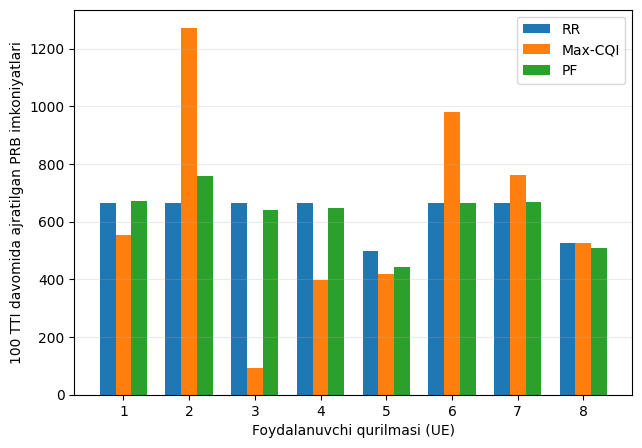

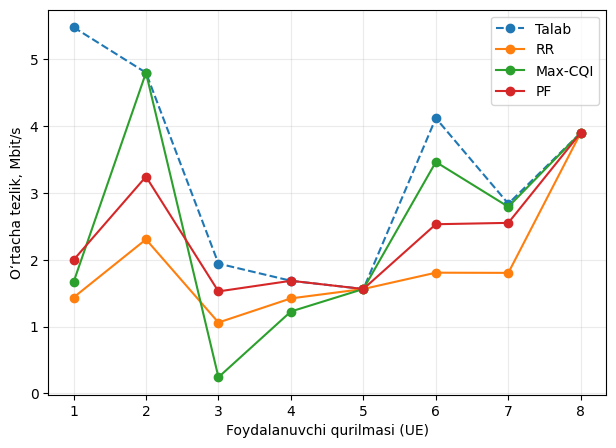

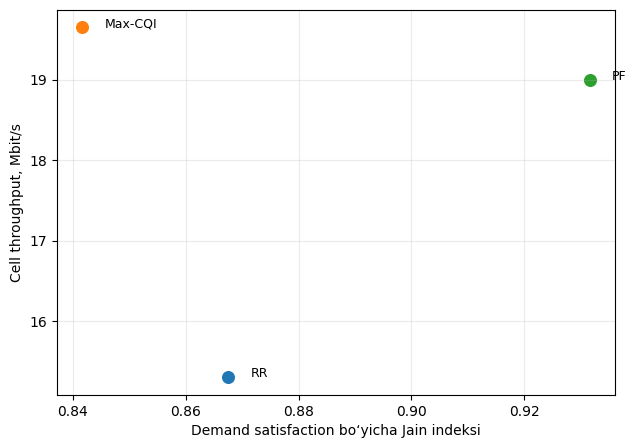

In [4]:
ues=np.arange(1,len(ue_df)+1); width=0.24
plt.figure(figsize=(7.2,5.0))
for j,s in enumerate(["RR","Max-CQI","PF"]):
    plt.bar(ues+(j-1)*width,results[s]["alloc_prbs"],width=width,label=s)
plt.xlabel('Foydalanuvchi qurilmasi (UE)'); plt.ylabel('100 TTI davomida ajratilgan PRB imkoniyatlari'); plt.xticks(ues); plt.legend(); plt.grid(axis="y",alpha=0.25); plt.show()

plt.figure(figsize=(7.2,5.0))
plt.plot(ues,scenario["demand_mbps"],marker="o",linestyle="--",label='Talab')
for s in ["RR","Max-CQI","PF"]:
    plt.plot(ues,results[s]["throughput_mbps"],marker="o",label=s)
plt.xlabel('Foydalanuvchi qurilmasi (UE)'); plt.ylabel('O‘rtacha tezlik, Mbit/s'); plt.xticks(ues); plt.legend(); plt.grid(alpha=0.25); plt.show()

plt.figure(figsize=(7.2,5.0))
for s in ["RR","Max-CQI","PF"]:
    k=results[s]["kpi"]
    plt.scatter(k["satisfaction_jain"],k["cell_throughput_mbps"],s=70,label=s)
    plt.text(k["satisfaction_jain"]+0.004,k["cell_throughput_mbps"],s,fontsize=9)
plt.xlabel('Demand satisfaction bo‘yicha Jain indeksi'); plt.ylabel('Cell throughput, Mbit/s'); plt.grid(alpha=0.25); plt.show()

## 5. Sensitivity va load-sweep tajribalari

Bandwidth ×2 tajribada CQI va bazaviy trafik talabi o‘zgarmaydi; faqat mavjud PRBlar soni oshadi. Load sweepda esa bir xil radio kanal sharoitida talab 0.5×, 1×, 1.5× va 2× ko‘paytiriladi.

Bandwidth sensitivity


,bandwidth_mhz,available_prbs,scheduler,cell_throughput_mbps,throughput_jain,satisfaction_jain,p5_satisfaction_pct,total_unmet_demand_mbps,resource_utilization_pct
0,10.0,50,RR,15.3001,0.8431,0.8675,32.3807,11.0302,100.00
1,10.0,50,Max-CQI,19.6526,0.7448,0.8417,18.7512,6.6777,100.00
2,10.0,50,PF,19.0020,0.8978,0.9316,45.1974,7.3283,100.00
3,20.0,100,RR,26.3303,0.8466,1.0000,100.0000,0.0000,97.81
4,20.0,100,Max-CQI,26.3303,0.8466,1.0000,100.0000,0.0000,81.99
5,20.0,100,PF,26.3303,0.8466,1.0000,100.0000,0.0000,87.15



Offered-load sweep


,load_factor,scheduler,cell_throughput_mbps,throughput_jain,satisfaction_jain,p5_satisfaction_pct,min_satisfaction_pct,starved_ue_pct,total_unmet_demand_mbps
0,0.5,RR,12.9471,0.8572,0.9993,94.8265,92.0407,0.0,0.2181
1,0.5,Max-CQI,13.1651,0.8466,1.0000,100.0000,100.0000,0.0,0.0000
2,0.5,PF,13.1651,0.8466,1.0000,100.0000,100.0000,0.0,0.0000
3,1.0,RR,15.3001,0.8431,0.8675,32.3807,26.1953,0.0,11.0302
4,1.0,Max-CQI,19.6526,0.7448,0.8417,18.7512,12.4985,0.0,6.6777
5,1.0,PF,19.0020,0.8978,0.9316,45.1974,36.4379,0.0,7.3283
6,1.5,RR,16.4803,0.7471,0.7696,20.1391,16.0988,0.0,23.0151
7,1.5,Max-CQI,21.4527,0.5655,0.6630,7.3144,3.6106,0.0,18.0427
8,1.5,PF,21.1651,0.8085,0.8359,28.2853,22.8566,0.0,18.3303
9,2.0,RR,16.4803,0.7471,0.7696,15.1043,12.0741,0.0,36.1802


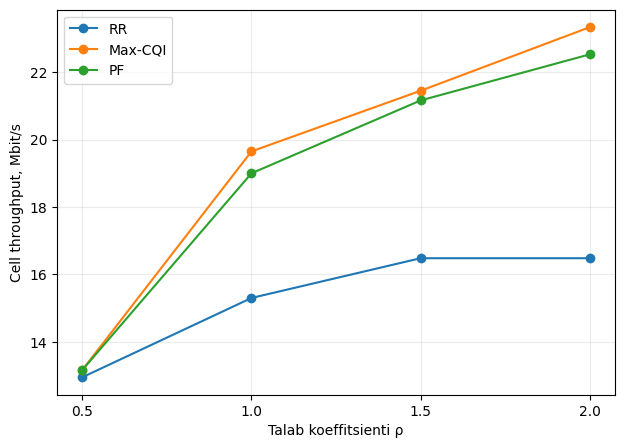

In [5]:
bw_df = bandwidth_sensitivity(v, n_tti=N_TTI)
load_df = load_sweep(v, load_factors=(0.5,1.0,1.5,2.0), n_tti=N_TTI)
print('Bandwidth sensitivity')
display(bw_df[["bandwidth_mhz","available_prbs","scheduler","cell_throughput_mbps","throughput_jain","satisfaction_jain","p5_satisfaction_pct","total_unmet_demand_mbps","resource_utilization_pct"]].round(4))
print('\n'+'Offered-load sweep')
display(load_df[["load_factor","scheduler","cell_throughput_mbps","throughput_jain","satisfaction_jain","p5_satisfaction_pct","min_satisfaction_pct","starved_ue_pct","total_unmet_demand_mbps"]].round(4))

plt.figure(figsize=(7.2,5.0))
for s in ["RR","Max-CQI","PF"]:
    d=load_df[load_df["scheduler"]==s]
    plt.plot(d["load_factor"],d["cell_throughput_mbps"],marker="o",label=s)
plt.xlabel('Talab koeffitsienti ρ'); plt.ylabel('Cell throughput, Mbit/s'); plt.xticks([0.5,1.0,1.5,2.0]); plt.legend(); plt.grid(alpha=0.25); plt.show()

## 6. Natijalarni saqlash va sanity-checklar

In [6]:
prefix=f"A4v2_variant_{VARIANT:02d}"
ue_df.to_csv(prefix+"_ue_parameters.csv",index=False)
cqi_stats_df.to_csv(prefix+"_cqi_summary.csv",index=False)
kpi_df.to_csv(prefix+"_scheduler_kpi.csv",index=False)
alloc_df.to_csv(prefix+"_allocations.csv",index=False)
bw_df.to_csv(prefix+"_bandwidth_sensitivity.csv",index=False)
load_df.to_csv(prefix+"_load_sweep.csv",index=False)

for s,res in results.items():
    k=res["kpi"]
    assert k["used_prb_opportunities"] <= k["available_prb_opportunities"]
    assert np.all(res["throughput_mbps"] >= -1e-12)
    assert np.all(res["throughput_mbps"] <= scenario["demand_mbps"] + 1e-9)
    assert 0 <= k["throughput_jain"] <= 1
    assert 0 <= k["satisfaction_jain"] <= 1
    assert 0 <= k["resource_utilization_pct"] <= 100
    assert np.all((scenario["cqi_cube"] >= 1) & (scenario["cqi_cube"] <= 15))

base_rows=bw_df[bw_df["bandwidth_mhz"]==v["bandwidth_mhz"]].set_index("scheduler")
load1=load_df[np.isclose(load_df["load_factor"],1.0)].set_index("scheduler")
for s,res in results.items():
    assert abs(base_rows.loc[s,"cell_throughput_mbps"]-res["kpi"]["cell_throughput_mbps"]) < 1e-9
    assert abs(load1.loc[s,"cell_throughput_mbps"]-res["kpi"]["cell_throughput_mbps"]) < 1e-9
print('Saqlandi'+':', prefix+'_ue_parameters.csv,', prefix+'_cqi_summary.csv,', prefix+'_scheduler_kpi.csv,', prefix+'_allocations.csv,', prefix+'_bandwidth_sensitivity.csv,', prefix+'_load_sweep.csv')

Saqlandi: A4v2_variant_01_ue_parameters.csv, A4v2_variant_01_cqi_summary.csv, A4v2_variant_01_scheduler_kpi.csv, A4v2_variant_01_allocations.csv, A4v2_variant_01_bandwidth_sensitivity.csv, A4v2_variant_01_load_sweep.csv


## 7. Talaba xulosasi

6–8 gapda schedulerlarni cell throughput, throughput Jain, satisfaction Jain, 5-percentile satisfaction, unmet demand va resource utilization bo‘yicha taqqoslang. Frequency-selective CQI va historical PFning rolini hamda bandwidth ×2 va load sweep natijalarini izohlang.